# 06 — Protocol v1.0, Stage 2F: text at the design stage (stratification)

This is the "stratification" use from the claim under test. Text changes **the design**, not the estimator.

| Design | Strata | Question |
|---|---|---|
| D1 | NTEE10 (MISSING as a level) × 3 size classes + take-all | Status quo |
| D1-imp | D1, with the 31% MISSING NTEE10 replaced by text-coded NTEE10 (logit on E*, no survey variable) | **S4:** text as a frame coder |
| D1-H44 | NTEE10 × 4 size classes + take-all | Equal-H twin of D2a |
| D2a | NTEE10 × 2 size × 2 classes of a frozen text score (last year's text head's predicted gov-grant ratio) | **S5:** prediction strata |

Every design has n = 1,000, a take-all of the top 1% on lagged expenses, and compromise allocation.

Estimators are run under each design: HT and GREG_size_cat@F1p (R = 2,000), and MCAL_bmfmax@F1p (R = 500). The MCAL rows test **M8**: are design gains absorbed by a strong estimator?

**Rules (protocol §9.4)**
- **S4:** GM over all 15 real y of RE(D1-imp ∣ D1) ≥ 1.05, for HT and for GREG.
- **S5:** GM over H of RE(D2a ∣ D1-H44) meets the production bar (point ≥ 1.10, lower bound ≥ 1.05).

Designs differ, so samples are independent across designs. The bootstrap resamples replicates jointly, which is valid for independent arms too.

In [1]:
import os, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
PROJ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(PROJ, "src"))
DATA = os.environ.get("EMBAUX_DATA", "/tmp/claude-0/data")
import plotstyle; plotstyle.use()
from protocol import H_SET, H_D, H_S, R_SET, gm_re, verdict
from analysis import cell_metrics
from report import Y_LABEL
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
OUT = f"{DATA}/results/stage2f_ne_v3"
RES = os.path.join(PROJ, "results", "stage2f_ne_v3"); os.makedirs(RES, exist_ok=True)
df = pd.read_parquet(f"{OUT}/mc.parquet"); truth = json.load(open(f"{OUT}/meta.json"))["truth"]
info = json.load(open(f"{OUT}/designs.json")); display(pd.DataFrame(info).T)
df["arm"] = df.estimator + "|" + df.design
ALL = list(truth)

,cv_accuracy_known,n_imputed,H,n,take_all_n
D1-imp,0.629808,6417.0,31.0,1000.0,206.0
D1,NaN,NaN,34.0,1000.0,206.0
D1-H44,NaN,NaN,45.0,1000.0,220.0
D2a,NaN,NaN,45.0,1000.0,206.0


## 1. Validity under each design

In [2]:
cm = cell_metrics(df.drop(columns="estimator").rename(columns={"arm": "estimator"}), truth)
cm[["est", "design"]] = cm.estimator.str.split("|", expand=True)
cm.to_csv(f"{RES}/cell_metrics.csv", index=False)
for col in ["rb_pct", "coverage_pct", "rrmse_pct"]:
    t = cm[cm.est == "GREG_size_cat@F1p"].pivot(index="y", columns="design", values=col); t.index = [Y_LABEL.get(i, i) for i in t.index]
    print(f"GREG_size_cat@F1p, {col}:"); display(t.round(2))

GREG_size_cat@F1p, rb_pct:


design,D1,D1-H44,D1-imp,D2a
Share with foreign activities,1.01,0.98,0.17,1.35
Share granting to individuals,0.52,0.23,0.43,0.75
Share with gov. grants,-0.03,-0.10,-0.36,0.05
Share with volunteers,0.03,-0.04,0.03,0.16
Share lobbying,0.50,-0.00,0.03,0.75
Contributions,0.51,0.35,0.20,0.53
Employees,-0.01,-0.02,0.00,-0.04
Total expenses,0.04,0.07,0.04,0.03
Fundraising expenses,1.10,1.10,0.95,1.80
Government grants,0.56,0.54,-0.00,0.39


GREG_size_cat@F1p, coverage_pct:


design,D1,D1-H44,D1-imp,D2a
Share with foreign activities,92.40,91.85,90.60,91.95
Share granting to individuals,93.55,93.30,92.50,93.40
Share with gov. grants,93.60,93.20,92.65,93.75
Share with volunteers,94.15,93.30,93.80,94.00
Share lobbying,93.35,91.95,92.00,93.10
Contributions,91.00,91.20,90.90,88.85
Employees,91.10,91.50,89.35,90.25
Total expenses,90.45,91.05,90.25,90.15
Fundraising expenses,87.65,90.35,89.10,86.30
Government grants,90.30,89.80,88.95,86.35


GREG_size_cat@F1p, rrmse_pct:


design,D1,D1-H44,D1-imp,D2a
Share with foreign activities,14.66,14.96,15.10,14.35
Share granting to individuals,12.44,11.99,12.36,12.29
Share with gov. grants,6.92,7.08,6.96,6.71
Share with volunteers,4.39,4.31,4.32,4.36
Share lobbying,12.31,12.50,13.20,12.33
Contributions,3.51,3.32,3.56,4.54
Employees,1.35,1.36,1.33,1.54
Total expenses,0.83,0.77,0.78,0.87
Fundraising expenses,6.36,6.29,6.31,8.63
Government grants,8.54,8.49,8.59,11.60


## 2. S4 and S5

In [3]:
rows = []
for est in ["HT", "GREG_size_cat@F1p", "MCAL_bmfmax@F1p"]:
    for name, (a, b) in {"S4: D1-imp vs D1": ("D1-imp", "D1"), "S5: D2a vs D1-H44": ("D2a", "D1-H44"),
                         "D1-H44 vs D1 (one more size class)": ("D1-H44", "D1"), "D2a vs D1": ("D2a", "D1")}.items():
        for lab, ys in [("all 15", ALL), ("H", H_SET), ("H_D", H_D), ("H_S", H_S), ("R", R_SET)]:
            pt, lo, hi, per = gm_re(df.drop(columns="estimator").rename(columns={"arm": "estimator"}), truth, f"{est}|{a}", f"{est}|{b}", ys)
            bar, anyg = verdict(pt, lo, hi)
            rows.append({"estimator": est, "comparison": name, "set": lab, "gm_re": pt, "lo95": lo, "hi95": hi,
                         "production_bar": bar, "any_gain": anyg, **{f"re:{k}": v for k, v in per.items()}})
S = pd.DataFrame(rows); S.to_csv(f"{RES}/s4_s5.csv", index=False)
show = S[((S.comparison.str.startswith("S4")) & (S.set == "all 15")) | ((S.comparison.str.startswith("S5")) & (S.set == "H"))]
display(show[["estimator", "comparison", "set", "gm_re", "lo95", "hi95", "production_bar", "any_gain"]].round(3))
s4 = S[(S.comparison.str.startswith("S4")) & (S.set == "all 15") & S.estimator.isin(["HT", "GREG_size_cat@F1p"])]
print("S4 (>= 1.05 for HT and GREG):", "PASS" if (s4.gm_re >= 1.05).all() else "FAIL")
s5 = S[(S.comparison.str.startswith("S5")) & (S.set == "H") & (S.estimator == "GREG_size_cat@F1p")].iloc[0]
print("S5 (production bar, GREG):", s5.production_bar, "| HT:", S[(S.comparison.str.startswith("S5")) & (S.set == "H") & (S.estimator == "HT")].iloc[0].production_bar)

,estimator,comparison,set,gm_re,lo95,hi95,production_bar,any_gain
0,HT,S4: D1-imp vs D1,all 15,0.997,0.970,1.029,EXCLUDED,NO
6,HT,S5: D2a vs D1-H44,H,0.709,0.688,0.729,EXCLUDED,NO
20,GREG_size_cat@F1p,S4: D1-imp vs D1,all 15,1.017,0.985,1.053,EXCLUDED,UNCLEAR
26,GREG_size_cat@F1p,S5: D2a vs D1-H44,H,0.767,0.744,0.791,EXCLUDED,NO
40,MCAL_bmfmax@F1p,S4: D1-imp vs D1,all 15,1.000,0.935,1.070,EXCLUDED,UNCLEAR
46,MCAL_bmfmax@F1p,S5: D2a vs D1-H44,H,0.731,0.686,0.776,EXCLUDED,NO


S4 (>= 1.05 for HT and GREG): FAIL
S5 (production bar, GREG): EXCLUDED | HT: EXCLUDED


### Per-variable RE, and whether a strong estimator absorbs design gains (M8)

In [4]:
for comp in ["S4: D1-imp vs D1", "S5: D2a vs D1-H44"]:
    t = S[(S.comparison == comp) & (S.set == "all 15")].set_index("estimator")[[f"re:{y}" for y in ALL]].T
    t.index = [Y_LABEL.get(i[3:], i[3:]) for i in t.index]
    print(comp); display(t.round(3))

S4: D1-imp vs D1


estimator,HT,GREG_size_cat@F1p,MCAL_bmfmax@F1p
Government grants,0.916,0.987,1.009
Contributions,0.932,0.974,0.930
Program service revenue,1.113,1.068,1.048
Fundraising expenses,0.997,1.016,1.028
Officer compensation,1.031,1.000,1.120
Volunteers (capped 10k),0.976,0.971,0.946
Share with volunteers,1.050,1.033,1.168
Share granting to individuals,1.036,1.014,1.027
Share with foreign activities,0.963,0.942,0.943
Share lobbying,0.894,0.869,0.912


S5: D2a vs D1-H44


estimator,HT,GREG_size_cat@F1p,MCAL_bmfmax@F1p
Government grants,0.447,0.536,0.522
Contributions,0.438,0.535,0.513
Program service revenue,0.490,0.654,0.627
Fundraising expenses,0.517,0.531,0.546
Officer compensation,0.709,0.809,0.837
Volunteers (capped 10k),0.873,0.843,0.710
Share with volunteers,0.968,0.978,0.927
Share granting to individuals,0.966,0.951,0.826
Share with foreign activities,1.131,1.087,1.096
Share lobbying,0.983,1.027,0.949


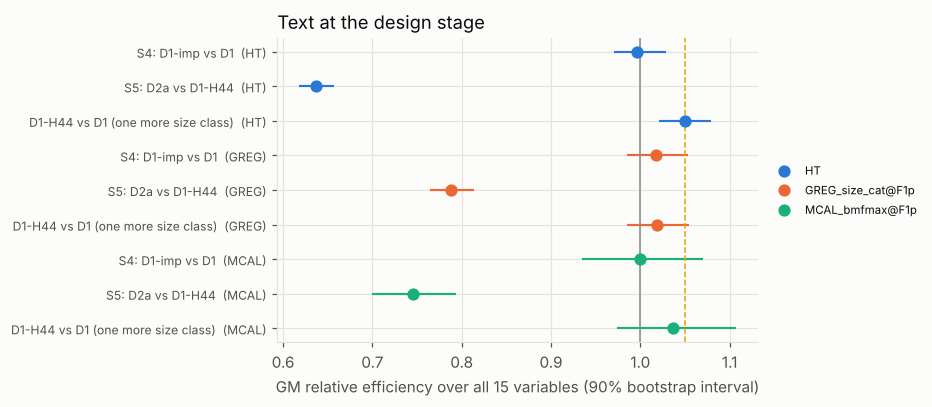

In [5]:
fig, ax = plt.subplots(figsize=(8.6, 3.8))
sub = S[S.set.isin(["all 15"]) & S.comparison.isin(["S4: D1-imp vs D1", "S5: D2a vs D1-H44", "D1-H44 vs D1 (one more size class)"])].reset_index(drop=True)
yy = np.arange(len(sub))
cols = {"HT": plotstyle.SERIES[0], "GREG_size_cat@F1p": plotstyle.SERIES[1], "MCAL_bmfmax@F1p": plotstyle.SERIES[2]}
for est, c in cols.items():
    m = sub.estimator == est
    ax.errorbar(sub.gm_re[m], yy[m], xerr=[sub.gm_re[m] - sub.lo95[m], sub.hi95[m] - sub.gm_re[m]], fmt="o", color=c, capsize=0, lw=1.4, label=est)
ax.axvline(1, color=plotstyle.NEUTRAL, lw=1); ax.axvline(1.05, color=plotstyle.SERIES[3], lw=1, ls="--")
ax.set_yticks(yy); ax.set_yticklabels(sub.comparison + "  (" + sub.estimator.str.split("_").str[0] + ")", fontsize=8); ax.invert_yaxis()
ax.set_xlabel("GM relative efficiency over all 15 variables (90% bootstrap interval)")
ax.set_title("Text at the design stage", loc="left"); ax.legend(fontsize=7.5, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout(); plt.savefig(f"{RES}/design_stage.png", dpi=150, bbox_inches="tight"); plt.show()